# Large pistons from per-wavelength models and a multi-wavelength unwrap

Same data as `trainMLP_multiwavelength.ipynb`: 5 petal pistons in +-5 um and
the 19 output-channel powers at 41 wavelengths. Instead of one model on the
whole spectrum, this notebook

1. fits one small polynomial model per wavelength. At wavelength lambda the
   signals depend on a piston only modulo lambda (the pupil phase is
   2 pi p / lambda), so each model regresses the *wrapped* piston, through
   its phasor (sin, cos)(2 pi p / lambda);
2. fuses the wrapped estimates of all wavelengths into the full-range piston
   (`ml_reconstruct.unwrap`: circular maximum likelihood over the whole
   range, then a robust refinement) -- like synthetic-wavelength
   interferometry;

and compares the result with the full-spectrum MLP and with a single global
polynomial model.

In [1]:
import os
os.environ["CBEAM_BACKEND"] = "numpy"

import numpy as np
import matplotlib.pyplot as plt
import ml_reconstruct as ml

M_MODES = 5
PISTON_SPAN_NM = 5000.0
DATASET = "data/ml/spectral_41wl.npz"          # made by trainMLP_multiwavelength.ipynb
cache = ml.ModelCache("data/ml/cache_perlambda", retrain=False)

ds = ml.LanternDataset.load(DATASET)
S_tr, C_tr = ds.train
S_va, C_va = ds.val
n_wl, n_cores = S_tr.shape[1:]
lam = ds.wavelengths_nm
xs = ml.Standardizer().fit(S_tr.reshape(len(S_tr), -1))     # per (wavelength, core) column
X3_tr = xs.transform(S_tr.reshape(len(S_tr), -1)).reshape(S_tr.shape)
X3_va = xs.transform(S_va.reshape(len(S_va), -1)).reshape(S_va.shape)
print(f"{len(S_tr)} training / {len(S_va)} validation samples, {n_wl} wavelengths "
      f"({lam[0]:.0f}-{lam[-1]:.0f} nm) x {n_cores} cores")

RESULTS = {"no skill (mean)": ml.rmse_nm(np.broadcast_to(C_tr.mean(0), C_va.shape), C_va)}

40000 training / 10000 validation samples, 41 wavelengths (700-900 nm) x 19 cores


## Reference: the full-spectrum MLP

Loaded from `trainMLP_multiwavelength.ipynb`'s model file (run that notebook
first to train it).

In [2]:
ys = ml.Standardizer().fit(C_tr)
MLP_FILE = "data/ml/cache_spectral/mlp-779x256x256x256x256x5-e10000-lr0.0003.npz"
params, layers, _ = ml.load_mlp(MLP_FILE)
C_mlp = ys.inverse(np.asarray(ml.mlp_forward(params, X3_va.reshape(len(X3_va), -1))))
RESULTS["MLP (all wl)"] = ml.rmse_nm(C_mlp, C_va)
print(f"MLP {layers}: mean RMSE {RESULTS['MLP (all wl)'].mean():.1f} nm")

MLP [779, 256, 256, 256, 256, 5]: mean RMSE 8.2 nm


## Per-wavelength models of the wrapped piston

One degree-3 OMP polynomial (at most K terms) of the core signals per
wavelength in `WL_USE`, regressing the phasor of each piston wrapped at that
wavelength's period, on a random `DATA_SHARE` of the training rows.

[cache] fitted and saved wrap1-d3-K1000-f19-n8000-w0


[cache] fitted and saved wrap1-d3-K1000-f19-n8000-w2


[cache] fitted and saved wrap1-d3-K1000-f19-n8000-w4


[cache] fitted and saved wrap1-d3-K1000-f19-n8000-w6


[cache] fitted and saved wrap1-d3-K1000-f19-n8000-w8


...

[cache] fitted and saved wrap1-d3-K1000-f19-n8000-w34


[cache] fitted and saved wrap1-d3-K1000-f19-n8000-w36


[cache] fitted and saved wrap1-d3-K1000-f19-n8000-w38


[cache] fitted and saved wrap1-d3-K1000-f19-n8000-w40


21 per-wavelength models (1122 s)

wrapped-piston RMSE per wavelength [nm]  (chance ~ period / sqrt(12))
   lambda | +-T/2 |    p0    p1    p2    p3    p4
    700.0 |   350 |   7.5   8.1   6.7   7.8   7.6
    710.0 |   355 |  10.2  10.0   8.7   9.6  10.2
    720.0 |   360 |   9.7  10.2   4.5   9.4  10.0
    730.0 |   365 |  10.6  11.8   9.6  11.3  10.5
    740.0 |   370 |  10.0  10.0   4.4  10.2  10.0
    750.0 |   375 |   7.0   7.6   5.3   7.5   6.8
    760.0 |   380 |  11.7  11.8   8.1  11.5  12.3
    770.0 |   385 |   8.7   8.8   6.1   8.1   9.0
    780.0 |   390 |   7.3   7.5   0.8   7.5   7.6
    790.0 |   395 |   6.0   7.4   3.1   7.7   6.1
    800.0 |   400 |  10.9  10.3   6.7  10.2  11.2
    810.0 |   405 |  10.4   9.7   3.6  10.5  10.8
    820.0 |   410 |   7.0   7.4   2.5   7.7   6.9
    830.0 |   415 |  10.1  11.4   5.2  11.2  10.8
    840.0 |   420 |  10.1   8.6   5.9   9.0  10.2
    850.0 |   425 |   8.5   9.8   4.5   7.8  10.4
    860.0 |   430 |   8.8   8.8   7.6   9.6  

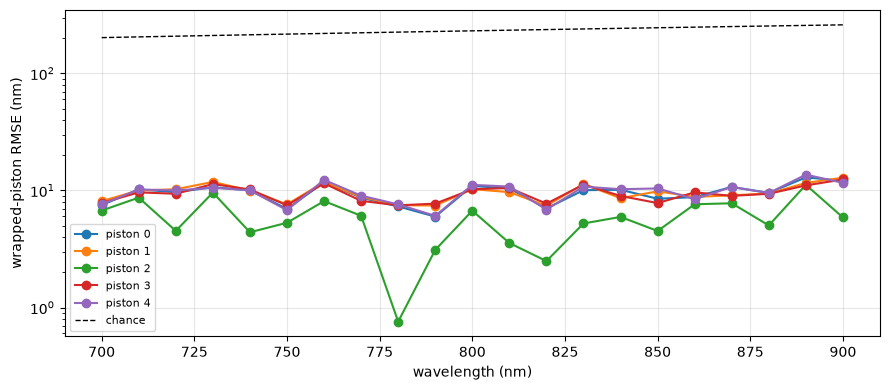

In [3]:
WRAP_FACTOR = 1.0                  # period = WRAP_FACTOR * lambda: the pupil phase is 2 pi p / lambda
                                   # (0.5 also works -- a function of p mod lambda/2 is one of
                                   # p mod lambda -- and gives the same accuracy)
WL_USE = np.arange(0, n_wl, 2)     # 21 of the 41 wavelengths
FIB_USE = np.arange(n_cores)       # all 19 cores
DEGREE, K, SCREEN = 3, 1000, 2000  # SCREEN >= 1539 terms: no screening at degree 3 / 19 inputs
DATA_SHARE = 0.2

periods = lam * WRAP_FACTOR
rows = ml.subsample_rows(len(X3_tr), DATA_SHARE, seed=0)
fit = ml.fit_wrapped_models(
    X3_tr, X3_va, C_tr, C_va, periods, WL_USE, FIB_USE, degree=DEGREE, K=K, screen=SCREEN,
    cache=cache, rows=rows,
    tag=f"wrap{WRAP_FACTOR:g}-d{DEGREE}-K{K}-f{len(FIB_USE)}-n{len(rows)}")
print(f"{len(WL_USE)} per-wavelength models ({fit['seconds']:.0f} s)\n")

print("wrapped-piston RMSE per wavelength [nm]  (chance ~ period / sqrt(12))")
print("   lambda | +-T/2 | " + " ".join(f"   p{k}" for k in range(M_MODES)))
for i, w in enumerate(WL_USE):
    print(f"  {lam[w]:7.1f} | {fit['periods'][i] / 2:5.0f} | " +
          " ".join(f"{fit['sig_va'][i, k]:5.1f}" for k in range(M_MODES)))
print(f"     mean |       | " + " ".join(f"{v:5.1f}" for v in fit["sig_va"].mean(0)))

plt.figure(figsize=(9, 4))
for k in range(M_MODES):
    plt.plot(lam[WL_USE], fit["sig_va"][:, k], "o-", label=f"piston {k}")
plt.plot(lam[WL_USE], fit["periods"] / np.sqrt(12), "k--", lw=1, label="chance")
plt.yscale("log"); plt.xlabel("wavelength (nm)"); plt.ylabel("wrapped-piston RMSE (nm)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Multi-wavelength unwrap

 piston | RMSE (nm) | bias (nm) | wrong fringe | best single wl, no unwrap
   0    |      1.93 |     +0.01 |       0.00% |      2910
   1    |      1.95 |     +0.02 |       0.00% |      2888
   2    |      0.61 |     +0.02 |       0.00% |      2881
   3    |      2.00 |     -0.00 |       0.00% |      2901
   4    |      1.94 |     +0.01 |       0.00% |      2867
  mean  |      1.68 |           |       0.00% |


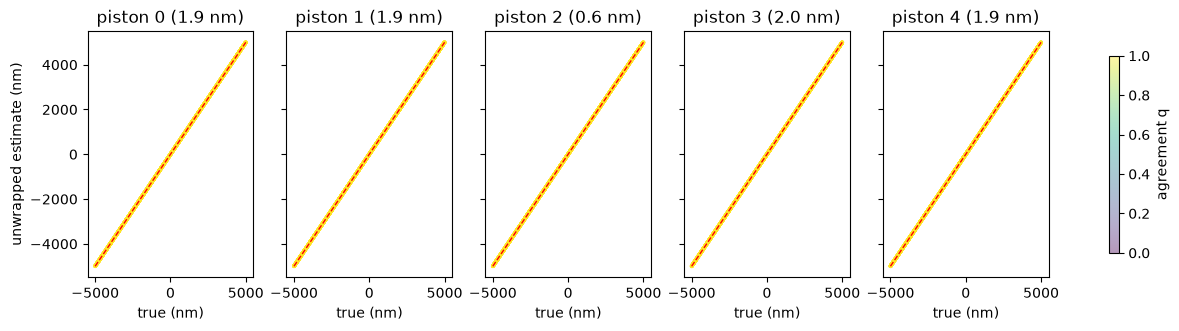

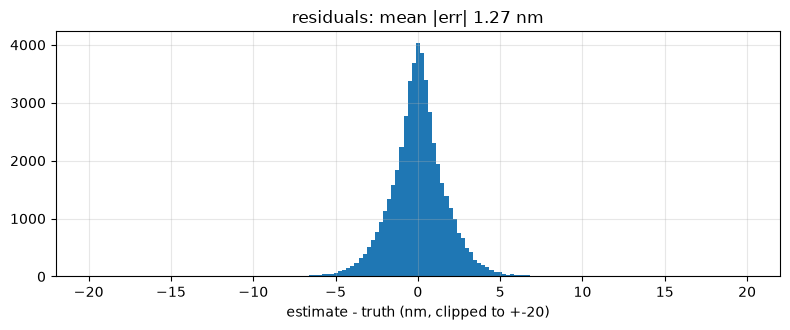

In [4]:
P_hat, Q = ml.unwrap_all(fit, PISTON_SPAN_NM)
RESULTS["per-wl OMP + unwrap"] = rmse = ml.rmse_nm(P_hat, C_va)
wrong = np.mean(np.abs(P_hat - C_va) > fit["periods"].min() / 2, axis=0)
best_w = fit["sig_va"].mean(axis=1).argmin()
no_unwrap = ml.rmse_nm(fit["ghat_va"][:, :, best_w], C_va)

print(" piston | RMSE (nm) | bias (nm) | wrong fringe | best single wl, no unwrap")
for k in range(M_MODES):
    print(f"   {k}    | {rmse[k]:9.2f} | {np.mean(P_hat[:, k] - C_va[:, k]):+9.2f} | "
          f"{100 * wrong[k]:10.2f}% | {no_unwrap[k]:9.0f}")
print(f"  mean  | {rmse.mean():9.2f} |           | {100 * wrong.mean():10.2f}% |")

fig, ax = plt.subplots(1, M_MODES, figsize=(3.1 * M_MODES, 3.2), sharex=True, sharey=True)
for k in range(M_MODES):
    sc = ax[k].scatter(C_va[:, k], P_hat[:, k], c=Q[:, k], s=3, alpha=0.4, vmin=0, vmax=1)
    ax[k].plot([-PISTON_SPAN_NM, PISTON_SPAN_NM], [-PISTON_SPAN_NM, PISTON_SPAN_NM], "r--", lw=1)
    ax[k].set_title(f"piston {k} ({rmse[k]:.1f} nm)"); ax[k].set_xlabel("true (nm)")
ax[0].set_ylabel("unwrapped estimate (nm)")
fig.colorbar(sc, ax=ax, label="agreement q", shrink=0.8); plt.show()

err = (P_hat - C_va).ravel()
plt.figure(figsize=(8, 3.4))
plt.hist(np.clip(err, -20, 20), bins=161)
plt.xlabel("estimate - truth (nm, clipped to +-20)"); plt.title(f"residuals: mean |err| {np.mean(np.abs(err)):.2f} nm")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## For comparison: one global polynomial model

A single degree-3 OMP model per piston on the core signals of several
wavelengths at once, regressing the piston directly. The number of terms
grows as (inputs)^3, so only a subset of wavelengths and cores fits in
memory.

In [5]:
WL_G, FIB_G, K_G, SCREEN_G = np.arange(0, n_wl, 8), np.arange(0, n_cores, 2), 1000, 6000
F_tr = X3_tr[rows][:, WL_G][:, :, FIB_G].reshape(len(rows), -1)
F_va = X3_va[:, WL_G][:, :, FIB_G].reshape(len(X3_va), -1)
print(f"{len(WL_G)} wavelengths x {len(FIB_G)} cores = {F_tr.shape[1]} inputs -> "
      f"{ml.n_poly_terms(F_tr.shape[1], 3):,} degree-3 terms, {len(rows)} training rows")
glob = cache(f"global-d3-K{K_G}-w{len(WL_G)}-f{len(FIB_G)}-n{len(rows)}",
             lambda: ml.fit_omp_poly(F_tr, C_tr[rows], 3, K_G, SCREEN_G))
RESULTS["global OMP"] = ml.rmse_nm(ml.predict_omp_poly(glob, F_va), C_va)
print(f"global OMP: mean RMSE {RESULTS['global OMP'].mean():.1f} nm")

6 wavelengths x 10 cores = 60 inputs -> 39,710 degree-3 terms, 8000 training rows


[cache] fitted and saved global-d3-K1000-w6-f10-n8000


global OMP: mean RMSE 2300.3 nm


## Comparison

[cache] fitted and saved linear-w21
  no skill (mean)         2882.22 nm   per piston [2898.51 2880.77 2874.84 2895.67 2861.29]
  MLP (all wl)               8.22 nm   per piston [ 5.94  5.11 16.08  8.15  5.81]
  per-wl OMP + unwrap        1.68 nm   per piston [1.93 1.95 0.61 2.   1.94]
  global OMP              2300.35 nm   per piston [2396.52 2385.23 1920.69 2425.21 2374.08]
  linear                  2803.84 nm   per piston [2835.38 2807.55 2768.44 2817.91 2789.93]


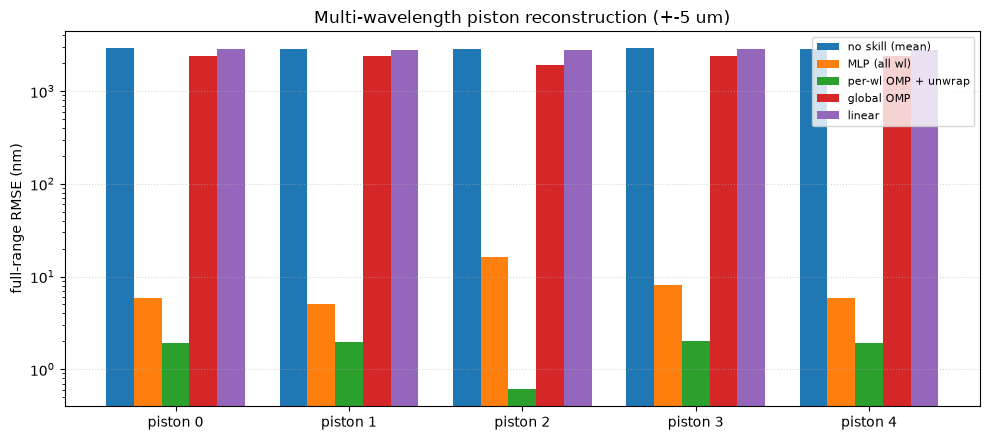

In [6]:
from sklearn.linear_model import Ridge
X_lin_tr = X3_tr[:, WL_USE].reshape(len(X3_tr), -1)
lin = cache(f"linear-w{len(WL_USE)}", lambda: Ridge(1.0).fit(X_lin_tr, C_tr))
RESULTS["linear"] = ml.rmse_nm(lin.predict(X3_va[:, WL_USE].reshape(len(X3_va), -1)), C_va)

for m, r in RESULTS.items():
    print(f"  {m:22s} {r.mean():8.2f} nm   per piston {np.round(r, 2)}")
names = list(RESULTS)
x, w = np.arange(M_MODES), 0.8 / len(names)
plt.figure(figsize=(10, 4.5))
for i, m in enumerate(names):
    plt.bar(x + (i - len(names) / 2 + 0.5) * w, RESULTS[m], w, label=m)
plt.yscale("log"); plt.xticks(x, [f"piston {k}" for k in x]); plt.ylabel("full-range RMSE (nm)")
plt.title("Multi-wavelength piston reconstruction (+-5 um)"); plt.legend(fontsize=8)
plt.grid(True, axis="y", ls=":", alpha=0.5); plt.tight_layout(); plt.show()